# INT315 Cluster Computing - Project: Visualizations
Udayveer Singh Chaudhary · Reg. No. 12320106 · Roll No. 43 · Section K3P23RE

Draws the charts of the Spark results with matplotlib. **Run the Spark programs first** (`spark_flights_analysis.ipynb` and `flights_graphx.scala`), because this notebook reads the files in `results/`. Open it from the `INT315_project` folder, then Run All. Each chart is shown below its cell and also saved in `figs/`.

Install once: `pip install pandas numpy matplotlib`.

In [4]:
import json, os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# open this notebook from the INT315_project folder (needs results/ from the Spark programs)
os.makedirs("figs", exist_ok=True)
R = json.load(open("results/metrics.json"))
BLUE, ORANGE, GREEN, RED, GREY, PURPLE = "#2F6DB5", "#F58220", "#3C9D5D", "#C8483E", "#8A8F98", "#7A5AA6"
plt.rcParams.update({"font.size": 11, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.alpha": 0.25, "axes.axisbelow": True, "figure.dpi": 100, "savefig.dpi": 200})
DAYS = ["Sun", "Mon", "Tue", "Wed", "Thu", "Fri", "Sat"]


def done(fig, name):
    fig.tight_layout()
    fig.savefig(f"figs/{name}.png", bbox_inches="tight")
    plt.show()   # show the chart in the notebook
    plt.close(fig)
    print("saved", name)

### Figure 1: delay histogram

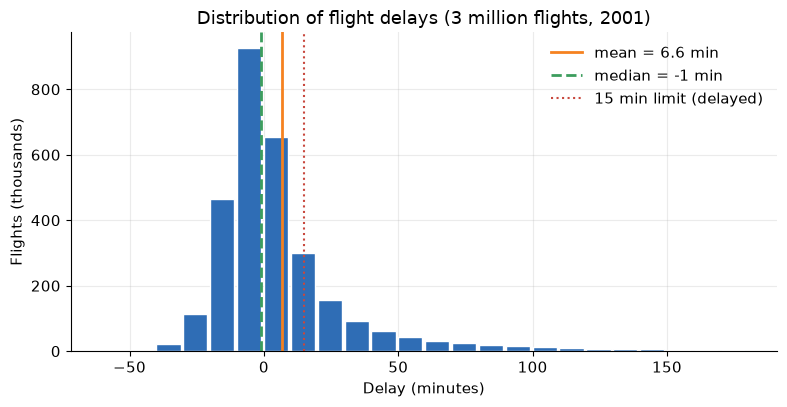

saved f01_delay_distribution


In [5]:
# 1 delay histogram ---------------------------------------------------------
h = pd.read_csv("results/delay_hist.csv")
fig, ax = plt.subplots(figsize=(8, 4.2))
ax.bar(h.left, h.flights / 1e3, width=9, align="edge", color=BLUE, edgecolor="white")
ax.axvline(R["mean_delay"], color=ORANGE, lw=2, label=f"mean = {R['mean_delay']:.1f} min")
ax.axvline(R["median"], color=GREEN, lw=2, ls="--", label=f"median = {R['median']:.0f} min")
ax.axvline(15, color=RED, lw=1.5, ls=":", label="15 min limit (delayed)")
ax.set_xlabel("Delay (minutes)"); ax.set_ylabel("Flights (thousands)")
ax.set_title("Distribution of flight delays (3 million flights, 2001)"); ax.legend(frameon=False)
done(fig, "f01_delay_distribution")

### Figure 2: by hour

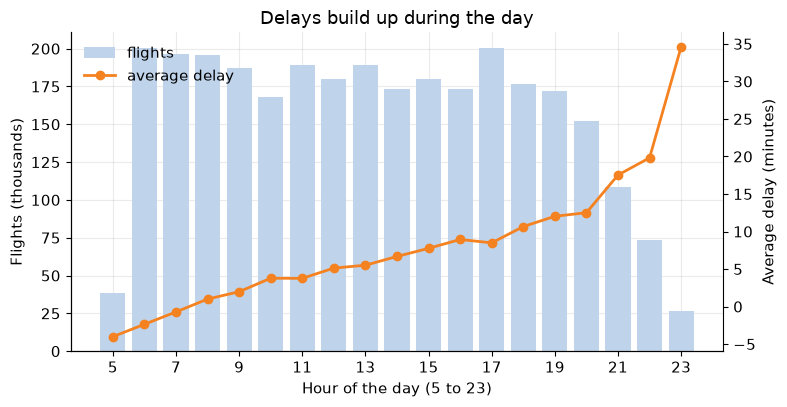

saved f02_delay_by_hour


In [6]:
# 2 by hour -----------------------------------------------------------------
bh_all = pd.read_csv("results/by_hour.csv")
bh = bh_all[bh_all.hour >= 5]          # hours 0-4 have very few flights, so they are left out of the chart
fig, ax = plt.subplots(figsize=(8, 4.2))
ax.bar(bh.hour, bh.flights / 1e3, color="#BFD3EA", label="flights")
ax.set_xlabel("Hour of the day (5 to 23)"); ax.set_ylabel("Flights (thousands)")
ax2 = ax.twinx(); ax2.grid(False)
ax2.plot(bh.hour, bh.avg_delay, color=ORANGE, marker="o", lw=2, label="average delay")
ax2.set_ylabel("Average delay (minutes)"); ax2.spines["right"].set_visible(True)
ax.set_xticks(range(5, 24, 2)); ax.set_title("Delays build up during the day")
lines = ax.get_legend_handles_labels(); l2 = ax2.get_legend_handles_labels()
ax.legend(lines[0] + l2[0], lines[1] + l2[1], frameon=False, loc="upper left")
done(fig, "f02_delay_by_hour")

### Figure 3: day of week + daily trend

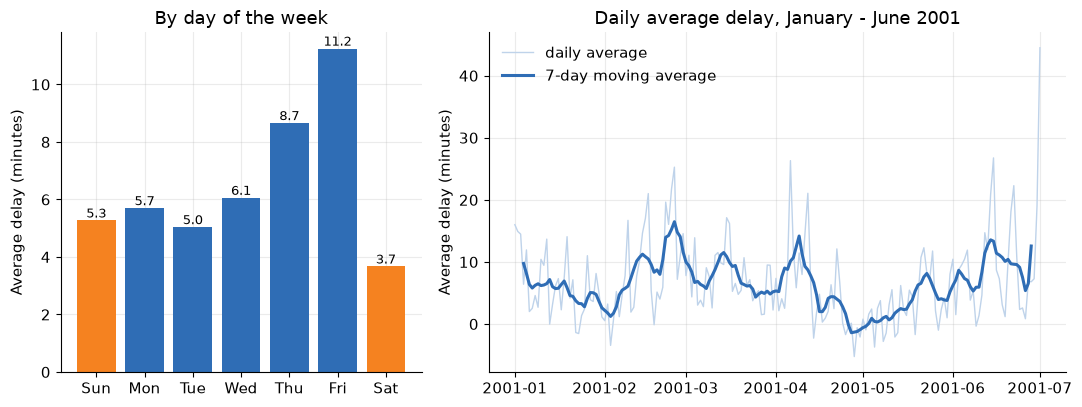

saved f03_delay_by_weekday_and_date


In [7]:
# 3 day of week + daily trend -----------------------------------------------
bd = pd.read_csv("results/by_dow.csv")
day = pd.read_csv("results/by_day.csv", parse_dates=["day"])
fig, axs = plt.subplots(1, 2, figsize=(11, 4.2), gridspec_kw={"width_ratios": [1, 1.6]})
cols = [ORANGE if d in (1, 7) else BLUE for d in bd.dow]
axs[0].bar([DAYS[d - 1] for d in bd.dow], bd.avg_delay, color=cols)
for i, v in enumerate(bd.avg_delay):
    axs[0].text(i, v + 0.1, f"{v:.1f}", ha="center", fontsize=9)
axs[0].set_ylabel("Average delay (minutes)"); axs[0].set_title("By day of the week")
axs[1].plot(day.day, day.avg_delay, color="#BFD3EA", lw=1, label="daily average")
axs[1].plot(day.day, day.avg_delay.rolling(7, center=True).mean(), color=BLUE, lw=2.2, label="7-day moving average")
axs[1].set_ylabel("Average delay (minutes)"); axs[1].set_title("Daily average delay, January - June 2001")
axs[1].legend(frameon=False)
done(fig, "f03_delay_by_weekday_and_date")

### Figure 4: airports

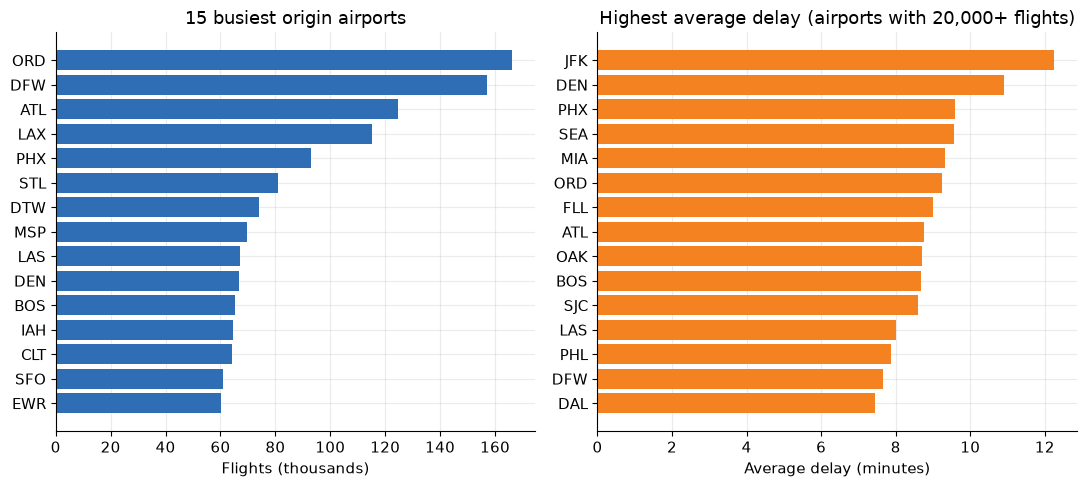

saved f04_airports


In [8]:
# 4 airports -----------------------------------------------------------------
bo = pd.read_csv("results/by_origin.csv")
top = bo.head(15).iloc[::-1]
worst = bo[bo.flights >= 20000].sort_values("avg_delay", ascending=False).head(15).iloc[::-1]
fig, axs = plt.subplots(1, 2, figsize=(11, 5))
axs[0].barh(top.origin, top.flights / 1e3, color=BLUE); axs[0].set_xlabel("Flights (thousands)"); axs[0].set_title("15 busiest origin airports")
axs[1].barh(worst.origin, worst.avg_delay, color=ORANGE); axs[1].set_xlabel("Average delay (minutes)")
axs[1].set_title("Highest average delay (airports with 20,000+ flights)")
done(fig, "f04_airports")

### Figure 5: routes

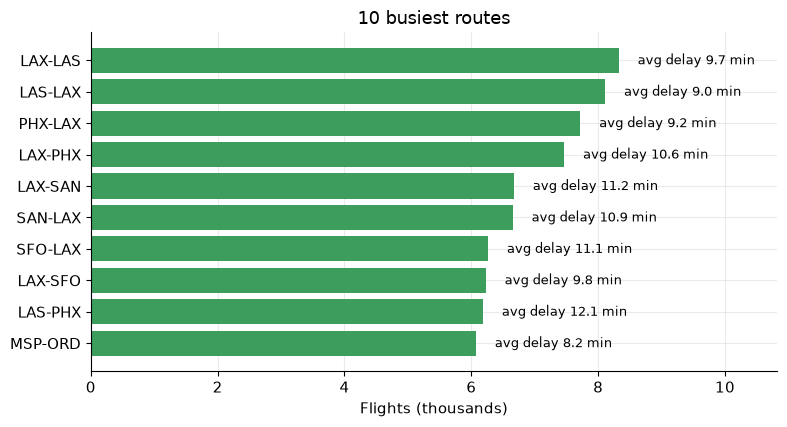

saved f05_busiest_routes


In [9]:
# 5 routes --------------------------------------------------------------------
rt = pd.read_csv("results/top_routes.csv").head(10).iloc[::-1]
fig, ax = plt.subplots(figsize=(8, 4.4))
ax.barh(rt.route, rt.flights / 1e3, color=GREEN)
for i, (f, d) in enumerate(zip(rt.flights, rt.avg_delay)):
    ax.text(f / 1e3 + 0.3, i, f"avg delay {d:.1f} min", va="center", fontsize=9)
ax.set_xlabel("Flights (thousands)"); ax.set_title("10 busiest routes"); ax.set_xlim(0, rt.flights.max() / 1e3 * 1.3)
done(fig, "f05_busiest_routes")

### Figure 6: network map

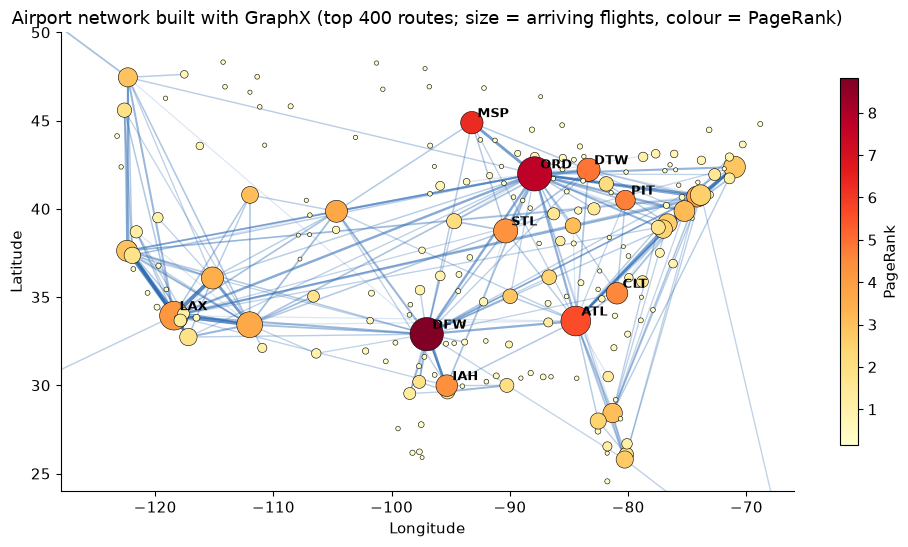

saved f06_airport_network


In [11]:
# 6 network map -----------------------------------------------------------------
ap = pd.read_csv("data/airports.csv")
nodes = pd.read_csv("results/graph_nodes.csv").merge(ap[["iata", "latitude", "longitude"]], on="iata", how="left").dropna()
edges = pd.read_csv("results/graph_edges.csv").merge(ap[["iata", "latitude", "longitude"]].rename(columns={"iata": "origin", "latitude": "lat1", "longitude": "lon1"}), on="origin") \
    .merge(ap[["iata", "latitude", "longitude"]].rename(columns={"iata": "destination", "latitude": "lat2", "longitude": "lon2"}), on="destination")
fig, ax = plt.subplots(figsize=(10, 5.6))
mx = edges.flights.max()
for r in edges.itertuples():
    ax.plot([r.lon1, r.lon2], [r.lat1, r.lat2], color=BLUE, alpha=0.05 + 0.5 * r.flights / mx, lw=0.4 + 2.2 * r.flights / mx)
sc = ax.scatter(nodes.longitude, nodes.latitude, s=8 + nodes.flights_in / nodes.flights_in.max() * 600, c=nodes.pagerank, cmap="YlOrRd", edgecolor="k", linewidth=0.4, zorder=3)
for r in nodes.sort_values("pagerank", ascending=False).head(10).itertuples():
    ax.annotate(r.iata, (r.longitude, r.latitude), xytext=(4, 4), textcoords="offset points", fontsize=9, weight="bold")
ax.set_xlim(-128, -66); ax.set_ylim(24, 50); ax.set_xlabel("Longitude"); ax.set_ylabel("Latitude"); ax.grid(False)
ax.set_title("Airport network built with GraphX (top 400 routes; size = arriving flights, colour = PageRank)")
fig.colorbar(sc, ax=ax, label="PageRank", shrink=0.8)
done(fig, "f06_airport_network")

### Figure 7: pagerank

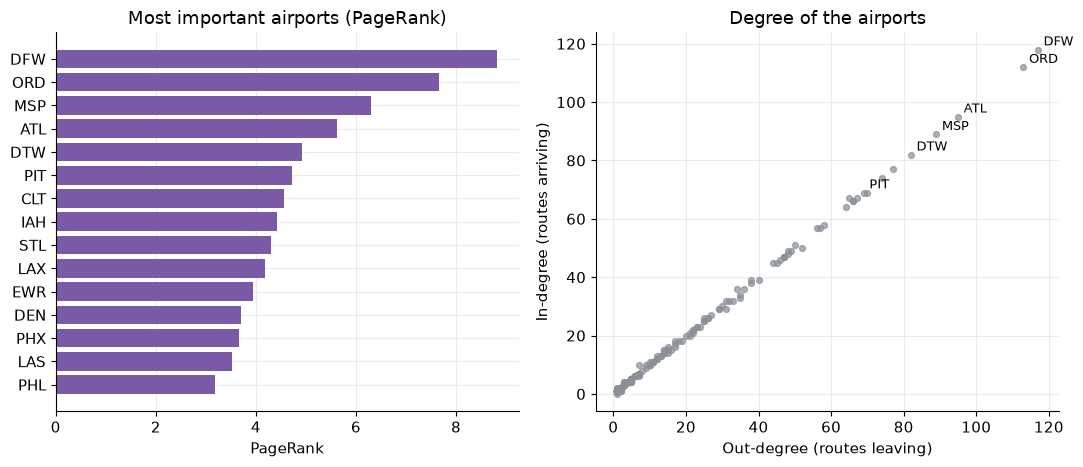

saved f07_pagerank_degree


In [12]:
# 7 pagerank --------------------------------------------------------------------
pr = nodes.sort_values("pagerank", ascending=False).head(15).iloc[::-1]
fig, axs = plt.subplots(1, 2, figsize=(11, 4.8))
axs[0].barh(pr.iata, pr.pagerank, color=PURPLE); axs[0].set_xlabel("PageRank"); axs[0].set_title("Most important airports (PageRank)")
axs[1].scatter(nodes.out_degree, nodes.in_degree, c=GREY, s=18, alpha=0.7)
for r in nodes.sort_values("pagerank", ascending=False).head(6).itertuples():
    axs[1].annotate(r.iata, (r.out_degree, r.in_degree), xytext=(4, 3), textcoords="offset points", fontsize=9)
axs[1].set_xlabel("Out-degree (routes leaving)"); axs[1].set_ylabel("In-degree (routes arriving)"); axs[1].set_title("Degree of the airports")
done(fig, "f07_pagerank_degree")

### Figure 8: correlation heat map

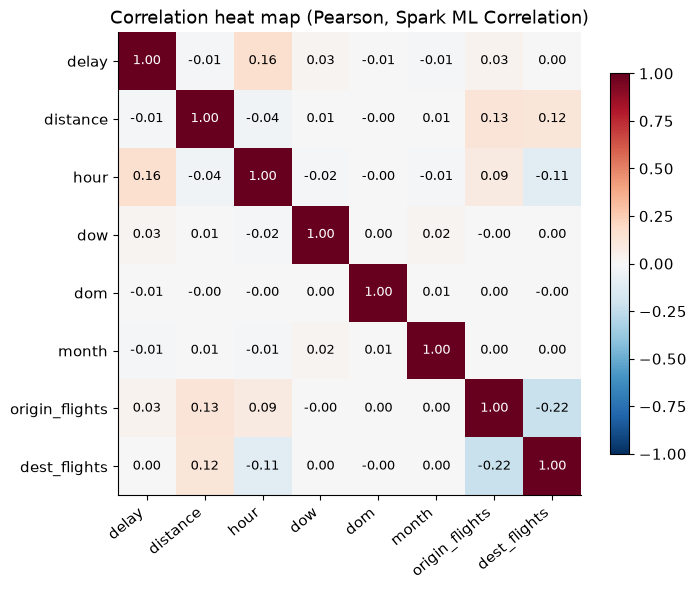

saved f08_correlation_heatmap


In [13]:
# 8 correlation heat map -----------------------------------------------------------
cm = pd.read_csv("results/correlation.csv", index_col=0)
fig, ax = plt.subplots(figsize=(7.2, 6))
im = ax.imshow(cm.values, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(cm))); ax.set_xticklabels(cm.columns, rotation=40, ha="right"); ax.set_yticks(range(len(cm))); ax.set_yticklabels(cm.index)
for i in range(len(cm)):
    for j in range(len(cm)):
        ax.text(j, i, f"{cm.values[i, j]:.2f}", ha="center", va="center", fontsize=9, color="white" if abs(cm.values[i, j]) > 0.6 else "black")
ax.grid(False); ax.set_title("Correlation heat map (Pearson, Spark ML Correlation)")
fig.colorbar(im, ax=ax, shrink=0.8)
done(fig, "f08_correlation_heatmap")

### Figure 9: caching benchmark

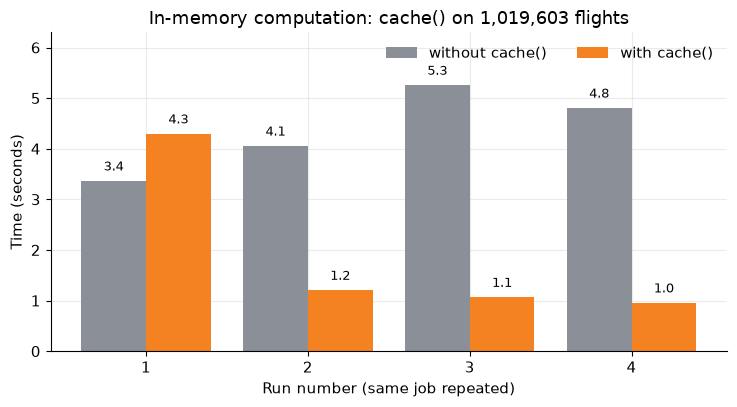

saved f09_cache_benchmark


In [14]:
# 9 caching benchmark ----------------------------------------------------------------
cb = R["cache_benchmark"]
fig, ax = plt.subplots(figsize=(7.5, 4.2))
x = np.arange(1, 5)
ax.bar(x - 0.2, cb["no_cache"], 0.4, color=GREY, label="without cache()")
ax.bar(x + 0.2, cb["with_cache"], 0.4, color=ORANGE, label="with cache()")
for xi, v in zip(x - 0.2, cb["no_cache"]): ax.text(xi, v + 0.2, f"{v:.1f}", ha="center", fontsize=9)
for xi, v in zip(x + 0.2, cb["with_cache"]): ax.text(xi, v + 0.2, f"{v:.1f}", ha="center", fontsize=9)
ax.set_xticks(x); ax.set_xlabel("Run number (same job repeated)"); ax.set_ylabel("Time (seconds)")
ax.set_ylim(0, 6.3); ax.set_title(f"In-memory computation: cache() on {cb['rows']:,} flights"); ax.legend(frameon=False, ncol=2, loc="upper right")
done(fig, "f09_cache_benchmark")

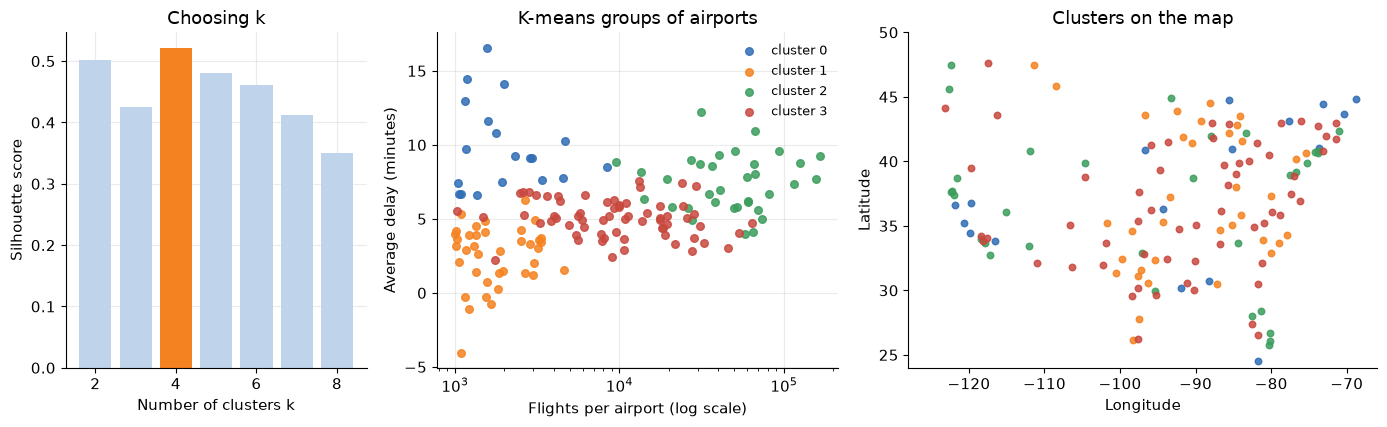

saved f10_kmeans


In [15]:
# 10 k-means --------------------------------------------------------------------------
km = pd.read_csv("results/kmeans_airports.csv")
sil = R["kmeans"]["silhouette"]
pal = [BLUE, ORANGE, GREEN, RED, PURPLE, GREY, "#C9B037", "#17A2B8"]
fig, axs = plt.subplots(1, 3, figsize=(14, 4.4), gridspec_kw={"width_ratios": [0.9, 1.2, 1.4]})
ks = [int(k) for k in sil]
axs[0].bar(ks, [sil[str(k)] for k in ks], color=[ORANGE if k == R["kmeans"]["k"] else "#BFD3EA" for k in ks])
axs[0].set_xlabel("Number of clusters k"); axs[0].set_ylabel("Silhouette score"); axs[0].set_title("Choosing k")
for c in sorted(km.cluster.unique()):
    s = km[km.cluster == c]
    axs[1].scatter(s.flights, s.avg_delay, s=30, color=pal[c], label=f"cluster {c}", alpha=0.85)
axs[1].set_xscale("log"); axs[1].set_xlabel("Flights per airport (log scale)"); axs[1].set_ylabel("Average delay (minutes)")
axs[1].set_title("K-means groups of airports"); axs[1].legend(frameon=False, fontsize=9)
for c in sorted(km.cluster.unique()):
    s = km[km.cluster == c].dropna(subset=["latitude"])
    axs[2].scatter(s.longitude, s.latitude, s=22, color=pal[c], alpha=0.85)
axs[2].set_xlim(-128, -66); axs[2].set_ylim(24, 50); axs[2].grid(False)
axs[2].set_xlabel("Longitude"); axs[2].set_ylabel("Latitude"); axs[2].set_title("Clusters on the map")
done(fig, "f10_kmeans")

### Figure 11: regression metrics

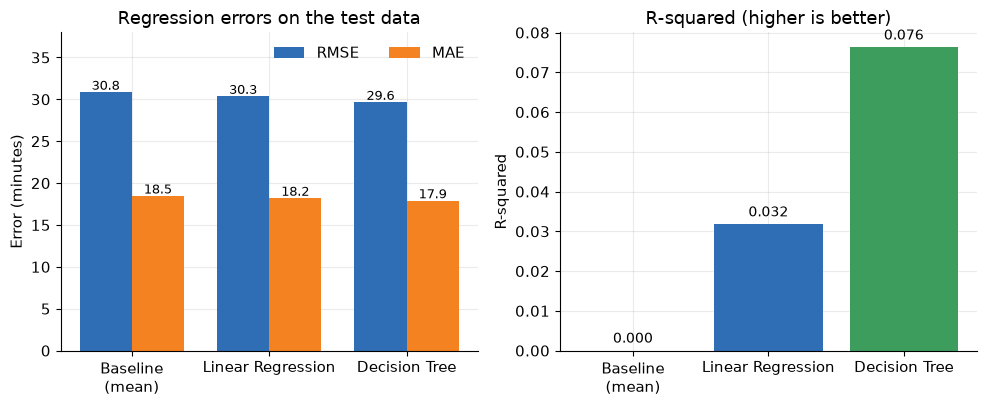

saved f11_regression_metrics


In [16]:
# 11 regression metrics -----------------------------------------------------------------
reg = R["regression"]
names = list(reg.keys())
fig, axs = plt.subplots(1, 2, figsize=(10, 4.2))
w = 0.38; x = np.arange(len(names))
axs[0].bar(x - w / 2, [reg[n]["rmse"] for n in names], w, color=BLUE, label="RMSE")
axs[0].bar(x + w / 2, [reg[n]["mae"] for n in names], w, color=ORANGE, label="MAE")
for i, n in enumerate(names):
    axs[0].text(i - w / 2, reg[n]["rmse"] + 0.3, f"{reg[n]['rmse']:.1f}", ha="center", fontsize=9)
    axs[0].text(i + w / 2, reg[n]["mae"] + 0.3, f"{reg[n]['mae']:.1f}", ha="center", fontsize=9)
axs[0].set_xticks(x); axs[0].set_xticklabels([n.replace(" Regressor", "").replace(" (mean)", "\n(mean)") for n in names]); axs[0].set_ylabel("Error (minutes)")
axs[0].set_ylim(0, 38); axs[0].set_title("Regression errors on the test data"); axs[0].legend(frameon=False, ncol=2, loc="upper right")
axs[1].bar(x, [reg[n]["r2"] for n in names], color=[GREY, BLUE, GREEN])
for i, n in enumerate(names): axs[1].text(i, reg[n]["r2"] + 0.002, f"{reg[n]['r2']:.3f}", ha="center", fontsize=10)
axs[1].set_xticks(x); axs[1].set_xticklabels([n.replace(" Regressor", "").replace(" (mean)", "\n(mean)") for n in names]); axs[1].set_ylabel("R-squared"); axs[1].set_title("R-squared (higher is better)")
done(fig, "f11_regression_metrics")

### Figure 12: classification metrics

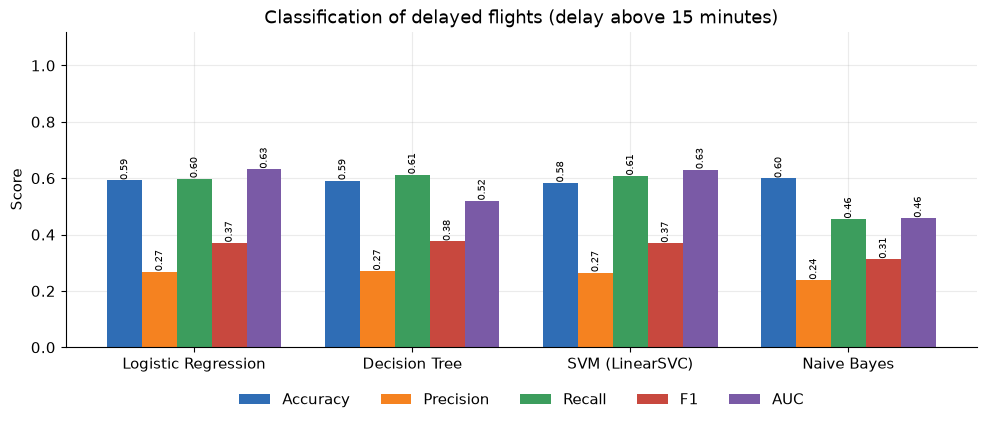

saved f12_classification_metrics


In [17]:
# 12 classification metrics ----------------------------------------------------------------
cls = R["classification"]
order = [n for n in cls if "no weights" not in n]
metrics = ["accuracy", "precision", "recall", "f1", "auc"]
fig, ax = plt.subplots(figsize=(10, 4.4))
w = 0.16
for i, m in enumerate(metrics):
    vals = [cls[n][m] for n in order]
    ax.bar(np.arange(len(order)) + (i - 2) * w, vals, w, label=m.upper() if m in ("f1", "auc") else m.capitalize(), color=[BLUE, ORANGE, GREEN, RED, PURPLE][i])
    for xi, v in zip(np.arange(len(order)) + (i - 2) * w, vals): ax.text(xi, v + 0.01, f"{v:.2f}", ha="center", fontsize=7.5, rotation=90)
ax.set_xticks(range(len(order))); ax.set_xticklabels(order); ax.set_ylim(0, 1.12); ax.set_ylabel("Score")
ax.set_title("Classification of delayed flights (delay above 15 minutes)"); ax.legend(frameon=False, ncol=5, loc="upper center", bbox_to_anchor=(0.5, -0.1))
done(fig, "f12_classification_metrics")

### Figure 13: confusion matrices

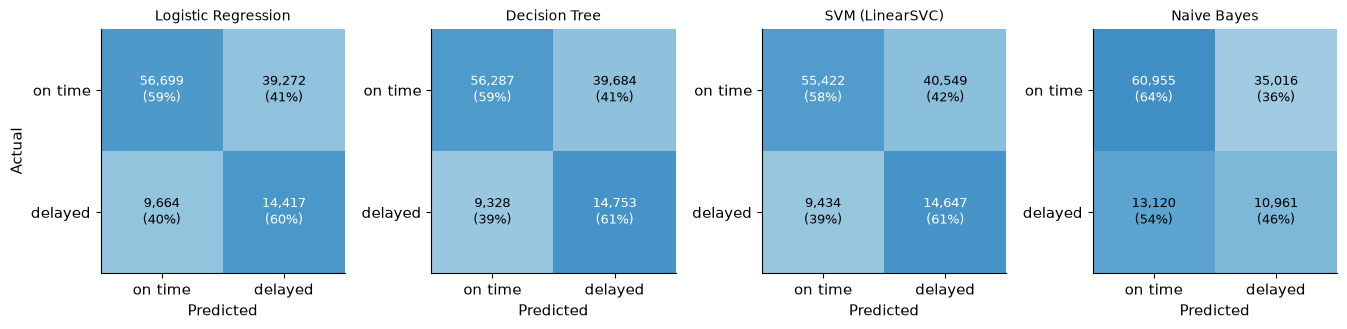

saved f13_confusion_matrices


In [18]:
# 13 confusion matrices ---------------------------------------------------------------------
cf = R["confusion"]
show = [n for n in cf if "no weights" not in n]
fig, axs = plt.subplots(1, len(show), figsize=(3.4 * len(show), 3.7))
for ax, n in zip(np.atleast_1d(axs), show):
    m = np.array(cf[n]); pct = m / m.sum(axis=1, keepdims=True)
    ax.imshow(pct, cmap="Blues", vmin=0, vmax=1)
    for i in range(2):
        for j in range(2):
            ax.text(j, i, f"{m[i, j]:,}\n({pct[i, j]*100:.0f}%)", ha="center", va="center", fontsize=9, color="white" if pct[i, j] > 0.55 else "black")
    ax.set_xticks([0, 1]); ax.set_xticklabels(["on time", "delayed"]); ax.set_yticks([0, 1]); ax.set_yticklabels(["on time", "delayed"])
    ax.set_xlabel("Predicted"); ax.set_title(n, fontsize=10); ax.grid(False)
np.atleast_1d(axs)[0].set_ylabel("Actual")
done(fig, "f13_confusion_matrices")

### Figure 14: feature importance

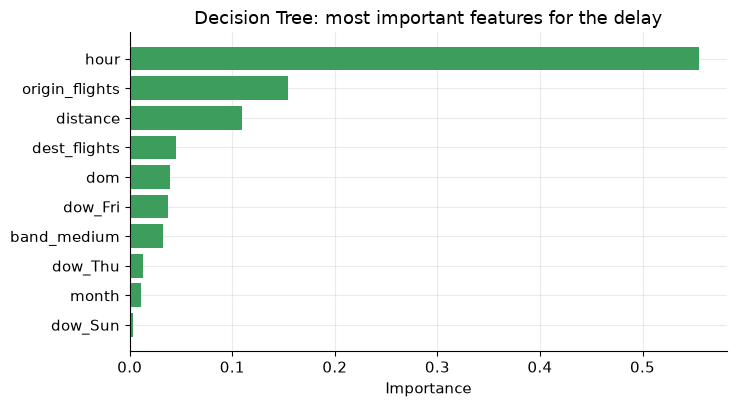

saved f14_feature_importance


In [19]:
# 14 feature importance ------------------------------------------------------------------------
fi = pd.read_csv("results/dt_importance.csv").head(10).iloc[::-1]
fig, ax = plt.subplots(figsize=(7.5, 4.2))
ax.barh(fi.feature, fi.importance, color=GREEN); ax.set_xlabel("Importance"); ax.set_title("Decision Tree: most important features for the delay")
done(fig, "f14_feature_importance")

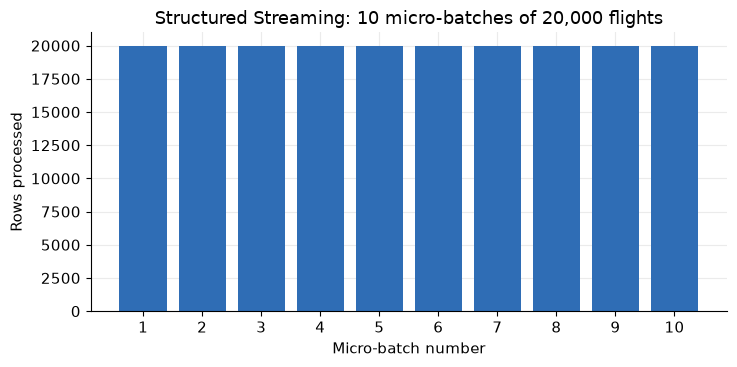

saved f15_streaming_batches
all figures done


In [20]:
# 15 batch vs streaming micro-batches ---------------------------------------------------------------
st = R["stream"]
fig, ax = plt.subplots(figsize=(7.5, 3.8))
ax.bar(range(1, len(st["rows_per_batch"]) + 1), st["rows_per_batch"], color=BLUE)
ax.set_xlabel("Micro-batch number"); ax.set_ylabel("Rows processed"); ax.set_title("Structured Streaming: 10 micro-batches of 20,000 flights")
ax.set_xticks(range(1, len(st["rows_per_batch"]) + 1))
done(fig, "f15_streaming_batches")
print("all figures done")